In [16]:
import subprocess, sys

def pip_install(*pkgs):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pkgs], check=True)

pip_install("transformers", "accelerate", "bitsandbytes", "datasets", "sentencepiece", "scikit-learn", "protobuf")
print("installed.")

installed.


In [17]:
import os, math, json, random, pickle
os.environ["HF_HOME"] = "/kaggle/working/hf_cache"
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
    AutoModel, BartTokenizer, BartForConditionalGeneration,
)

torch.manual_seed(0); random.seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

CKPT_DIR = "/kaggle/working/ckpt"
os.makedirs(CKPT_DIR, exist_ok=True)

def save_ckpt(name, obj):
    with open(f"{CKPT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)

def load_ckpt(name):
    path = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

Device: cuda


## Config — tune these first if you're short on time

In [18]:
N_TRAIN = 250
N_TEST = 100
K_SAMPLES = 10          # paper uses 10 samples/model for r_prob & r_trans
MAX_NEW_TOKENS = 60
BATCH_SIZE_GEN = 8
BATCH_SIZE_SCORE = 8
ROUTER_EPOCHS = 6
ROUTER_LR = 2e-5
DO_PROB_ROUTER = True   # set False to skip straight to r_det if time is tight
DO_TRANS_ROUTER = True  # requires DO_PROB_ROUTER = True
print("config set.")

config set.


## 1. Data — MixInstruct

In [19]:
cached = load_ckpt("examples")
if cached:
    train_examples, test_examples = cached
    print(f"loaded from checkpoint: train={len(train_examples)}  test={len(test_examples)}")
else:
    print("=== Loading MixInstruct ===")
    ds_train = load_dataset("llm-blender/mix-instruct", split="train")
    ds_test = load_dataset("llm-blender/mix-instruct", split="validation")

    def build_query(ex):
        instr = (ex.get("instruction") or "").strip()
        inp = (ex.get("input") or "").strip()
        return (instr + "\n" + inp).strip() if instr else inp

    def sample_examples(ds, n):
        idx = random.sample(range(len(ds)), min(n, len(ds)))
        out = []
        for i in idx:
            ex = ds[i]
            q = build_query(ex)
            ref = (ex.get("output") or "").strip()
            if q and ref:
                out.append({"query": q, "reference": ref})
        return out

    train_examples = sample_examples(ds_train, N_TRAIN)
    test_examples = sample_examples(ds_test, N_TEST)
    save_ckpt("examples", (train_examples, test_examples))
    print(f"train={len(train_examples)}  test={len(test_examples)}")

loaded from checkpoint: train=250  test=100


## 2. Load models — S: FLAN-T5-large (small)   L: Llama-2-7b-chat (large)

Using the NousResearch mirror of Llama-2 to skip Meta's gated-access approval wait.
Swap `LARGE_ID` to `"meta-llama/Llama-2-7b-chat-hf"` later after you have approved access.

**If this cell OOMs on `load_in_8bit=True`:** drop that kwarg and load plain
`torch_dtype=torch.float16, device_map="auto"` instead — fp16 7b fits in 16GB with room to spare.

In [20]:
print("=== Loading models (this can take a few minutes) ===")
SMALL_ID = "google/flan-t5-large"
LARGE_ID = "NousResearch/Llama-2-7b-chat-hf"

import shutil

def load_with_retry(model_class, model_id, **kwargs):
    """
    Handles: SafetensorError: Error while deserializing header: incomplete metadata,
    file not fully covered.
    This means a previous download of a safetensors shard for this model got
    interrupted (network blip / session restart) and a *partial* file is sitting in
    the HF cache. transformers will keep loading that same broken file forever unless
    we delete it or pass force_download=True. We try a normal load first, and only
    nuke+redownload on failure so re-running this cell is fast once the cache is healthy.
    """
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] initial load failed ({type(e).__name__}: {e}).")
        print(f"  [{model_id}] clearing cached snapshot and re-downloading cleanly...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        repo_folder = "models--" + model_id.replace("/", "--")
        target = os.path.join(cache_root, repo_folder)
        if os.path.exists(target):
            shutil.rmtree(target)
            print(f"  removed {target}")
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

small_tok = AutoTokenizer.from_pretrained(SMALL_ID)
small_model = load_with_retry(
    AutoModelForSeq2SeqLM, SMALL_ID, torch_dtype=torch.float16
).to(DEVICE)
small_model.eval()

large_tok = AutoTokenizer.from_pretrained(LARGE_ID)
if large_tok.pad_token is None:
    large_tok.pad_token = large_tok.eos_token
large_tok.padding_side = "left"   # required for batched causal-LM generation

from transformers import BitsAndBytesConfig
quant_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)

large_model = load_with_retry(
    AutoModelForCausalLM, LARGE_ID,
    torch_dtype=torch.float16,
    quantization_config=quant_config,
    device_map="auto",
)
large_model.eval()
print("models loaded.")print("=== Loading models (this can take a few minutes) ===")
SMALL_ID = "google/flan-t5-large"
LARGE_ID = "NousResearch/Llama-2-7b-chat-hf"

import shutil

def load_with_retry(model_class, model_id, **kwargs):
    """Retries with a clean re-download if the cached safetensors file is corrupted."""
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] initial load failed ({type(e).__name__}: {e}).")
        print(f"  [{model_id}] clearing cached snapshot and re-downloading cleanly...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        repo_folder = "models--" + model_id.replace("/", "--")
        target = os.path.join(cache_root, repo_folder)
        if os.path.exists(target):
            shutil.rmtree(target)
            print(f"  removed {target}")
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

small_tok = AutoTokenizer.from_pretrained(SMALL_ID)
small_model = load_with_retry(
    AutoModelForSeq2SeqLM, SMALL_ID, torch_dtype=torch.float16
).to(DEVICE)
small_model.eval()

large_tok = AutoTokenizer.from_pretrained(LARGE_ID)
if large_tok.pad_token is None:
    large_tok.pad_token = large_tok.eos_token
large_tok.padding_side = "left"   # required for batched causal-LM generation

from transformers import BitsAndBytesConfig
quant_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16)

large_model = load_with_retry(
    AutoModelForCausalLM, LARGE_ID,
    torch_dtype=torch.float16,
    quantization_config=quant_config,
    device_map="auto",
)
large_model.eval()
print("models loaded.")

=== Loading models (this can take a few minutes) ===
  [google/flan-t5-large] initial load failed (SafetensorError: Error while deserializing header: incomplete metadata, file not fully covered).
  [google/flan-t5-large] clearing cached snapshot and re-downloading cleanly...
  removed /kaggle/working/hf_cache/hub/models--google--flan-t5-large


config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/662 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

...

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/200 [00:00<?, ?B/s]

models loaded.


## 3. Generation functions

In [21]:
@torch.no_grad()
def generate_small(queries, num_return_sequences=1, do_sample=False):
    all_out = [[] for _ in queries]
    for i in range(0, len(queries), BATCH_SIZE_GEN):
        batch = queries[i:i + BATCH_SIZE_GEN]
        enc = small_tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=512).to(DEVICE)
        out = small_model.generate(
            **enc, max_new_tokens=MAX_NEW_TOKENS,
            do_sample=do_sample, top_p=0.9 if do_sample else None,
            temperature=0.9 if do_sample else None,
            num_return_sequences=num_return_sequences,
        )
        texts = small_tok.batch_decode(out, skip_special_tokens=True)
        for j in range(len(batch)):
            all_out[i + j] = texts[j * num_return_sequences:(j + 1) * num_return_sequences]
    return all_out

@torch.no_grad()
def generate_large(queries, num_return_sequences=1, do_sample=False):
    all_out = [[] for _ in queries]
    prompts = [f"[INST] {q} [/INST]" for q in queries]
    for i in range(0, len(prompts), BATCH_SIZE_GEN):
        batch = prompts[i:i + BATCH_SIZE_GEN]
        enc = large_tok(batch, return_tensors="pt", padding=True, truncation=True, max_length=512).to(large_model.device)
        out = large_model.generate(
            **enc, max_new_tokens=MAX_NEW_TOKENS,
            do_sample=do_sample, top_p=0.9 if do_sample else None,
            temperature=0.9 if do_sample else None,
            num_return_sequences=num_return_sequences,
            pad_token_id=large_tok.pad_token_id,
            remove_invalid_values=True, 
        )
        in_len = enc["input_ids"].shape[1]
        texts = large_tok.batch_decode(out[:, in_len:], skip_special_tokens=True)
        for j in range(len(batch)):
            all_out[i + j] = texts[j * num_return_sequences:(j + 1) * num_return_sequences]
    return all_out

print("generation functions defined.")

generation functions defined.


## 4. BART score — real source from neulab/BARTScore

In [22]:
class BARTScorer:
    def __init__(self, device="cuda:0", max_length=1024, checkpoint="facebook/bart-large-cnn"):
        self.device = device
        self.max_length = max_length
        self.tokenizer = BartTokenizer.from_pretrained(checkpoint)
        self.model = BartForConditionalGeneration.from_pretrained(checkpoint)
        self.model.eval().to(device)
        self.loss_fct = nn.NLLLoss(reduction="none", ignore_index=self.model.config.pad_token_id)
        self.lsm = nn.LogSoftmax(dim=1)

    def score(self, srcs, tgts, batch_size=4):
        score_list = []
        for i in range(0, len(srcs), batch_size):
            src_list = srcs[i:i + batch_size]
            tgt_list = tgts[i:i + batch_size]
            with torch.no_grad():
                enc_src = self.tokenizer(src_list, max_length=self.max_length, truncation=True, padding=True, return_tensors="pt")
                enc_tgt = self.tokenizer(tgt_list, max_length=self.max_length, truncation=True, padding=True, return_tensors="pt")
                src_ids = enc_src["input_ids"].to(self.device)
                src_mask = enc_src["attention_mask"].to(self.device)
                tgt_ids = enc_tgt["input_ids"].to(self.device)
                tgt_mask = enc_tgt["attention_mask"]
                tgt_len = tgt_mask.sum(dim=1).to(self.device)
                out = self.model(input_ids=src_ids, attention_mask=src_mask, labels=tgt_ids)
                logits = out.logits.view(-1, self.model.config.vocab_size)
                loss = self.loss_fct(self.lsm(logits), tgt_ids.view(-1))
                loss = loss.view(tgt_ids.shape[0], -1).sum(dim=1) / tgt_len.clamp(min=1)
                score_list += [-x.item() for x in loss]
        return score_list

print("=== Loading BARTScorer (facebook/bart-large-cnn) ===")
bart_scorer = BARTScorer(device=DEVICE)

def quality(hypotheses, references):
    """q(hypothesis) := BARTScore(reference -> hypothesis)."""
    return bart_scorer.score(references, hypotheses, batch_size=BATCH_SIZE_SCORE)

print("BARTScorer ready.")

=== Loading BARTScorer (facebook/bart-large-cnn) ===


[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/511 [00:00<?, ?it/s]

BARTScorer ready.


## 5. Generation pipeline function 

In [23]:
def run_pipeline(examples, k_samples, label):
    queries = [e["query"] for e in examples]
    refs = [e["reference"] for e in examples]

    print(f"--- [{label}] generating S x1 / L x1 (deterministic) ---")
    s_det = [g[0] for g in generate_small(queries, num_return_sequences=1, do_sample=False)]
    l_det = [g[0] for g in generate_large(queries, num_return_sequences=1, do_sample=False)]
    q_s_det = quality(s_det, refs)
    q_l_det = quality(l_det, refs)

    result = {"queries": queries, "refs": refs, "q_s_det": q_s_det, "q_l_det": q_l_det}

    if k_samples > 1:
        print(f"--- [{label}] generating S x{k_samples} / L x{k_samples} (sampled, for r_prob) ---")
        s_samp = generate_small(queries, num_return_sequences=k_samples, do_sample=True)
        l_samp = generate_large(queries, num_return_sequences=k_samples, do_sample=True)
        q_s_samp, q_l_samp = [], []
        for i in range(len(queries)):
            ref_rep = [refs[i]] * k_samples
            q_s_samp.append(quality(s_samp[i], ref_rep))
            q_l_samp.append(quality(l_samp[i], ref_rep))
        result["q_s_samp"] = q_s_samp
        result["q_l_samp"] = q_l_samp

    return result

print("run_pipeline defined.")

run_pipeline defined.


## 6. RUN generation — TRAIN set 

(Checkpointed)

In [24]:
train_data = load_ckpt("train_data")
if train_data:
    print("loaded train_data from checkpoint.")
else:
    train_data = run_pipeline(train_examples, K_SAMPLES if DO_PROB_ROUTER else 1, "train")
    save_ckpt("train_data", train_data)
    print("train_data generated and checkpointed.")

--- [train] generating S x1 / L x1 (deterministic) ---
--- [train] generating S x10 / L x10 (sampled, for r_prob) ---
train_data generated and checkpointed.


## 7. RUN generation — TEST set 

In [25]:
test_data = load_ckpt("test_data")
if test_data:
    print("loaded test_data from checkpoint.")
else:
    test_data = run_pipeline(test_examples, 1, "test")
    save_ckpt("test_data", test_data)
    print("test_data generated and checkpointed.")

--- [test] generating S x1 / L x1 (deterministic) ---
test_data generated and checkpointed.


## 8. Labels — y_det, y_prob, y_trans(t*)

In [26]:
def label_det(q_s, q_l):
    return [1.0 if s >= l else 0.0 for s, l in zip(q_s, q_l)]

def label_prob(q_s_samp, q_l_samp):
    out = []
    for s_list, l_list in zip(q_s_samp, q_l_samp):
        wins = sum(1 for s in s_list for l in l_list if s >= l)
        out.append(wins / (len(s_list) * len(l_list)))
    return out

def label_trans(q_s_samp, q_l_samp, t):
    out = []
    for s_list, l_list in zip(q_s_samp, q_l_samp):
        wins = sum(1 for s in s_list for l in l_list if s >= l - t)
        out.append(wins / (len(s_list) * len(l_list)))
    return out

y_det_train = label_det(train_data["q_s_det"], train_data["q_l_det"])
print(f"y_det positive rate (train): {np.mean(y_det_train):.3f}")

if DO_PROB_ROUTER:
    y_prob_train = label_prob(train_data["q_s_samp"], train_data["q_l_samp"])
    print(f"y_prob mean (train): {np.mean(y_prob_train):.3f}")

    if DO_TRANS_ROUTER:
        best_t, best_spread = 0.0, -1
        for t in np.linspace(0, 2.0, 21):
            y_t = np.array(label_trans(train_data["q_s_samp"], train_data["q_l_samp"], t))
            spread = np.mean(np.abs(y_t[:, None] - y_t[None, :]))
            if spread > best_spread:
                best_spread, best_t = spread, t
        print(f"t* = {best_t:.3f}  (spread={best_spread:.4f})")
        y_trans_train = label_trans(train_data["q_s_samp"], train_data["q_l_samp"], best_t)
        print(f"y_trans mean (train): {np.mean(y_trans_train):.3f}")

y_det positive rate (train): 0.308
y_prob mean (train): 0.259
t* = 1.400  (spread=0.4478)
y_trans mean (train): 0.500


## 9. Router model — DeBERTa-v3-small backbone

Plain PyTorch, not HF's `Trainer`/`TrainingArguments` — that API's kwarg names change across
`transformers` versions and broke on us once already; a manual loop only touches
`forward()`/`backward()`, which is far more stable.

In [29]:
ROUTER_ID = "microsoft/deberta-v3-small"

# Earlier float16 loads (FLAN-T5/Llama-2) can leave torch's global default dtype
# at float16, which would silently load this backbone in fp16 too -> dtype
# mismatch against the fp32 RouterHead. Force fp32 explicitly.
torch.set_default_dtype(torch.float32)

router_tok = AutoTokenizer.from_pretrained(ROUTER_ID)
router_backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)

class RouterHead(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.linear = nn.Linear(hidden_size, 1)
    def forward(self, pooled):
        return torch.sigmoid(self.linear(pooled)).squeeze(-1)

router_head = RouterHead(router_backbone.config.hidden_size).to(DEVICE)
router_head = router_head.float()

def encode_queries(queries, max_length=128):
    return router_tok(queries, return_tensors="pt", padding=True, truncation=True, max_length=max_length)

def router_forward(queries):
    enc = encode_queries(queries)
    enc = {k: v.to(DEVICE) for k, v in enc.items()}
    out = router_backbone(**enc)
    pooled = out.last_hidden_state[:, 0]
    return router_head(pooled)

print("router model ready.")

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


router model ready.


## 10. Train the router

In [30]:
def train_router(queries, labels, epochs=ROUTER_EPOCHS, lr=ROUTER_LR, name="router"):
    params = list(router_backbone.parameters()) + list(router_head.parameters())
    opt = torch.optim.AdamW(params, lr=lr)
    labels_t = torch.tensor(labels, dtype=torch.float32).to(DEVICE)
    n = len(queries)
    idx_all = list(range(n))
    print(f"--- training {name} for {epochs} epochs on {n} examples ---")
    for epoch in range(epochs):
        random.shuffle(idx_all)
        total_loss = 0.0
        for i in range(0, n, BATCH_SIZE_GEN):
            batch_idx = idx_all[i:i + BATCH_SIZE_GEN]
            batch_q = [queries[j] for j in batch_idx]
            batch_y = labels_t[batch_idx]
            preds = router_forward(batch_q)
            loss = F.binary_cross_entropy(preds, batch_y)
            opt.zero_grad(); loss.backward(); opt.step()
            total_loss += loss.item() * len(batch_idx)
        print(f"  epoch {epoch+1}/{epochs}  loss={total_loss/n:.4f}")

train_queries = train_data["queries"]
if DO_PROB_ROUTER and DO_TRANS_ROUTER:
    train_router(train_queries, y_trans_train, name="r_trans")
    active_router_name = "r_trans"
elif DO_PROB_ROUTER:
    train_router(train_queries, y_prob_train, name="r_prob")
    active_router_name = "r_prob"
else:
    train_router(train_queries, y_det_train, name="r_det")
    active_router_name = "r_det"

--- training r_trans for 6 epochs on 250 examples ---
  epoch 1/6  loss=0.6803
  epoch 2/6  loss=0.5313
  epoch 3/6  loss=0.3983
  epoch 4/6  loss=0.3440
  epoch 5/6  loss=0.3247
  epoch 6/6  loss=0.3093


## 11. Evaluate — cost advantage vs. quality drop, sweep threshold theta

In [31]:
@torch.no_grad()
def router_scores(queries):
    router_backbone.eval(); router_head.eval()
    scores = []
    for i in range(0, len(queries), BATCH_SIZE_GEN):
        batch = queries[i:i + BATCH_SIZE_GEN]
        scores += router_forward(batch).cpu().tolist()
    return scores

test_scores = np.array(router_scores(test_data["queries"]))
q_s_test = np.array(test_data["q_s_det"])
q_l_test = np.array(test_data["q_l_det"])
baseline_quality = q_l_test.mean()

print(f"=== Results ({active_router_name}) ===")
print(f"Baseline (always-large) mean quality: {baseline_quality:.4f}")
print(f"{'theta':>6} | {'cost adv %':>10} | {'mean quality':>12} | {'quality drop %':>14}")
rows = []
for theta in np.linspace(0.05, 0.95, 19):
    route_to_small = test_scores > theta
    cost_adv = route_to_small.mean() * 100
    realized_quality = np.where(route_to_small, q_s_test, q_l_test).mean()
    quality_drop = (baseline_quality - realized_quality) / abs(baseline_quality) * 100
    rows.append((theta, cost_adv, realized_quality, quality_drop))
    print(f"{theta:6.2f} | {cost_adv:10.1f} | {realized_quality:12.4f} | {quality_drop:14.2f}")

=== Results (r_trans) ===
Baseline (always-large) mean quality: -3.2474
 theta | cost adv % | mean quality | quality drop %
  0.05 |       88.0 |      -4.5761 |          40.92
  0.10 |       87.0 |      -4.5645 |          40.56
  0.15 |       87.0 |      -4.5645 |          40.56
  0.20 |       79.0 |      -4.3117 |          32.77
  0.25 |       75.0 |      -4.1828 |          28.80
  0.30 |       68.0 |      -4.0241 |          23.92
  0.35 |       60.0 |      -3.8663 |          19.06
  0.40 |       58.0 |      -3.7988 |          16.98
  0.45 |       55.0 |      -3.7044 |          14.07
  0.50 |       52.0 |      -3.6191 |          11.45
  0.55 |       50.0 |      -3.5916 |          10.60
  0.60 |       45.0 |      -3.5049 |           7.93
  0.65 |       38.0 |      -3.3711 |           3.81
  0.70 |       36.0 |      -3.2989 |           1.59
  0.75 |       30.0 |      -3.2487 |           0.04
  0.80 |       23.0 |      -3.1832 |          -1.98
  0.85 |       19.0 |      -3.1847 |        

## 12. Save results

In [32]:
os.makedirs("/kaggle/working", exist_ok=True)
with open("/kaggle/working/hybrid_llm_results.json", "w") as f:
    json.dump({
        "router": active_router_name,
        "n_train": len(train_queries), "n_test": len(test_data["queries"]),
        "baseline_quality": float(baseline_quality),
        "sweep": [{"theta": float(t), "cost_advantage_pct": float(c),
                   "mean_quality": float(q), "quality_drop_pct": float(d)} for t, c, q, d in rows],
    }, f, indent=2)
print("Saved -> /kaggle/working/hybrid_llm_results.json")
print("Done.")

Saved -> /kaggle/working/hybrid_llm_results.json
Done.


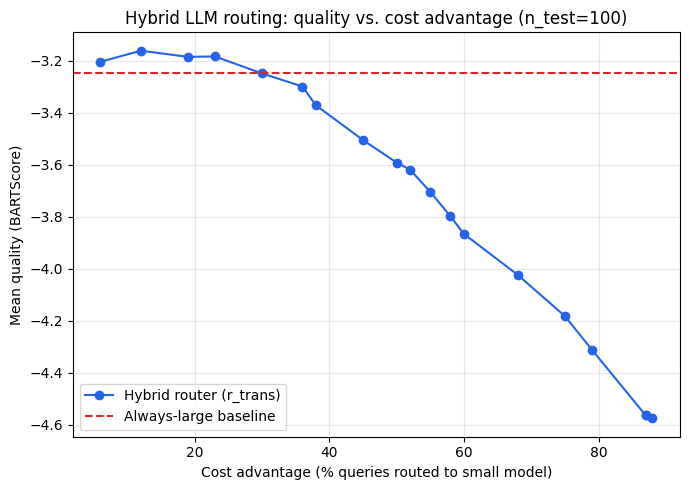


HYBRID LLM ROUTING SUMMARY  (router: r_trans)
Always-large baseline quality: -3.2474

 theta | cost adv % |    quality |  vs baseline
--------------------------------------------------
  0.95 |        6.0 |    -3.2034 |   1.35% better
  0.90 |       12.0 |    -3.1611 |   2.66% better
  0.85 |       19.0 |    -3.1847 |   1.93% better
  0.80 |       23.0 |    -3.1832 |   1.98% better
  0.75 |       30.0 |    -3.2487 |   0.04% drop
  0.70 |       36.0 |    -3.2989 |   1.59% drop
  0.65 |       38.0 |    -3.3711 |   3.81% drop
  0.60 |       45.0 |    -3.5049 |   7.93% drop
  0.55 |       50.0 |    -3.5916 |  10.60% drop
  0.50 |       52.0 |    -3.6191 |  11.45% drop
  0.45 |       55.0 |    -3.7044 |  14.07% drop
  0.40 |       58.0 |    -3.7988 |  16.98% drop
  0.35 |       60.0 |    -3.8663 |  19.06% drop
  0.30 |       68.0 |    -4.0241 |  23.92% drop
  0.25 |       75.0 |    -4.1828 |  28.80% drop
  0.20 |       79.0 |    -4.3117 |  32.77% drop
  0.10 |       87.0 |    -4.5645 |  40

In [35]:
import json
import matplotlib.pyplot as plt

with open("/kaggle/working/hybrid_llm_results.json") as f:
    res = json.load(f)

sweep = sorted(res["sweep"], key=lambda r: r["cost_advantage_pct"])
theta       = [r["theta"] for r in sweep]
cost_adv    = [r["cost_advantage_pct"] for r in sweep]
quality     = [r["mean_quality"] for r in sweep]
quality_drop = [r["quality_drop_pct"] for r in sweep]
baseline    = res["baseline_quality"]

# ---- Figure: cost advantage vs. quality (paper-style tradeoff curve) ----
fig, ax1 = plt.subplots(figsize=(7, 5))

ax1.plot(cost_adv, quality, marker="o", color="#2563eb", label="Hybrid router (r_trans)")
ax1.axhline(baseline, color="#dc2626", linestyle="--", label="Always-large baseline")
ax1.set_xlabel("Cost advantage (% queries routed to small model)")
ax1.set_ylabel("Mean quality (BARTScore)")
ax1.set_title(f"Hybrid LLM routing: quality vs. cost advantage (n_test={res['n_test']})")
ax1.legend(loc="lower left")
ax1.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("/kaggle/working/cost_quality_curve.png", dpi=150)
plt.show()

# ---- Summary table: key operating points ----
print(f"\n{'='*70}")
print(f"HYBRID LLM ROUTING SUMMARY  (router: {res['router']})")
print(f"{'='*70}")
print(f"Always-large baseline quality: {baseline:.4f}\n")
print(f"{'theta':>6} | {'cost adv %':>10} | {'quality':>10} | {'vs baseline':>12}")
print("-" * 50)
for r in sweep:
    sign = "better" if r["quality_drop_pct"] < 0 else "drop"
    print(f"{r['theta']:6.2f} | {r['cost_advantage_pct']:10.1f} | "
          f"{r['mean_quality']:10.4f} | {abs(r['quality_drop_pct']):6.2f}% {sign}")

best_free = min([r for r in sweep if r["quality_drop_pct"] <= 0],
                 key=lambda r: -r["cost_advantage_pct"], default=None)
if best_free:
    print(f"\n>>> Best 'no quality loss' point: theta={best_free['theta']:.2f} -> "
          f"{best_free['cost_advantage_pct']:.0f}% cost savings with "
          f"{'a quality gain of' if best_free['quality_drop_pct']<0 else 'quality drop of'} "
          f"{abs(best_free['quality_drop_pct']):.2f}%")